# 13. 계량→사이클 확인 + 물리 기반 변수로 모델 재구성

**PART 1** RG3 가스 샷의 사이클↑은 열분해(체류)가 아니라 계량 지연의 흔적인가
**PART 2** 12번 검증 결과로 변수 재설정 → 같은 reference·LORO·평가로 비교
- `E2_free` (v2 메인 재현) vs `E2_phys` (같은 구조, 물리 변수) vs `U_rule|phys` (학습 없는 물리 규칙) vs `E_phys+rule`
- 모델 입력은 전부 **인과적 변수(dev_*)** → 현장에서 그대로 계산 가능

In [1]:
%load_ext autoreload
%autoreload 2
import os, json
import pandas as pd
from run_compare import load_product
from scope import apply_scope
from model_phys import (metering_cycle_link, plot_metering_cycle, add_phys, run_phys_models)
from model_v2 import build_reference, reference_features, evaluate_v2, f1_v2, mask_transient
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
OUT = './outputs/phys_model'
os.makedirs(OUT, exist_ok=True)
PRODUCTS = ['cn7', 'rg3']

## PART 1. 계량시간 → 사이클

[cn7] 샷 1974, 불량 15
[rg3] 샷 627, 불량 32
① Run별 계량-사이클 상관


,제품,Run,샷,"ρ(계량,사이클) 전체",ρ 정상만,기울기(사이클초/계량초),계량 중앙값(s),사이클 중앙값(s),사이클 IQR(s)
0,cn7,cn7_R1,188.0,-0.147,-0.179,0.023,16.92,59.52,0.00
1,cn7,cn7_R2,418.0,-0.409,-0.409,-0.039,17.04,59.48,0.04
2,cn7,cn7_R3,309.0,-0.401,-0.401,-0.186,16.84,59.56,0.02
3,cn7,cn7_R4,189.0,-0.102,-0.102,0.019,16.92,59.52,0.00
4,cn7,cn7_R5,407.0,-0.223,-0.223,-0.705,16.82,59.48,0.02
5,cn7,cn7_R6,463.0,-0.233,-0.234,-0.092,16.59,59.52,0.02
6,cn7,합침(Run 안 z),NaN,-0.246,NaN,NaN,NaN,NaN,NaN
7,rg3,rg3_R1,41.0,-0.233,-0.233,-0.057,13.01,61.78,0.00
8,rg3,rg3_R2,103.0,-0.058,-0.044,-0.038,12.95,61.78,0.02
9,rg3,rg3_R3,197.0,-0.000,0.025,-0.006,12.92,61.78,0.02


② 사이클 구성요소 (Run 안 표준화 회귀)


,제품,구성요소,표준화 계수,within R²
0,cn7,Plasticizing_Time_raw,0.096,0.293
1,cn7,Injection_Time_raw,0.275,0.293
2,cn7,Filling_Time_raw,0.286,0.293
3,cn7,Clamp_Close_Time_raw,0.074,0.293
4,rg3,Plasticizing_Time_raw,-0.046,0.009
5,rg3,Injection_Time_raw,0.053,0.009
6,rg3,Filling_Time_raw,0.019,0.009
7,rg3,Clamp_Close_Time_raw,0.060,0.009


③ 불량 vs 정상 δ — 사이클에서 계량 영향을 빼도 남나


비교군                   ±10샷     전체
제품  불량군   변수                     
cn7 가스    계량시간       0.409  0.162
          사이클       -0.130  0.096
          사이클|계량 잔차  0.030 -0.006
    미성형계열 계량시간       0.032  0.240
          사이클       -0.266 -0.278
          사이클|계량 잔차 -0.379 -0.377
rg3 가스    계량시간       0.160  0.114
          사이클        0.214  0.182
          사이클|계량 잔차  0.191  0.129
    미성형계열 계량시간       0.361  0.463
          사이클        0.022  0.050
          사이클|계량 잔차  0.057  0.060

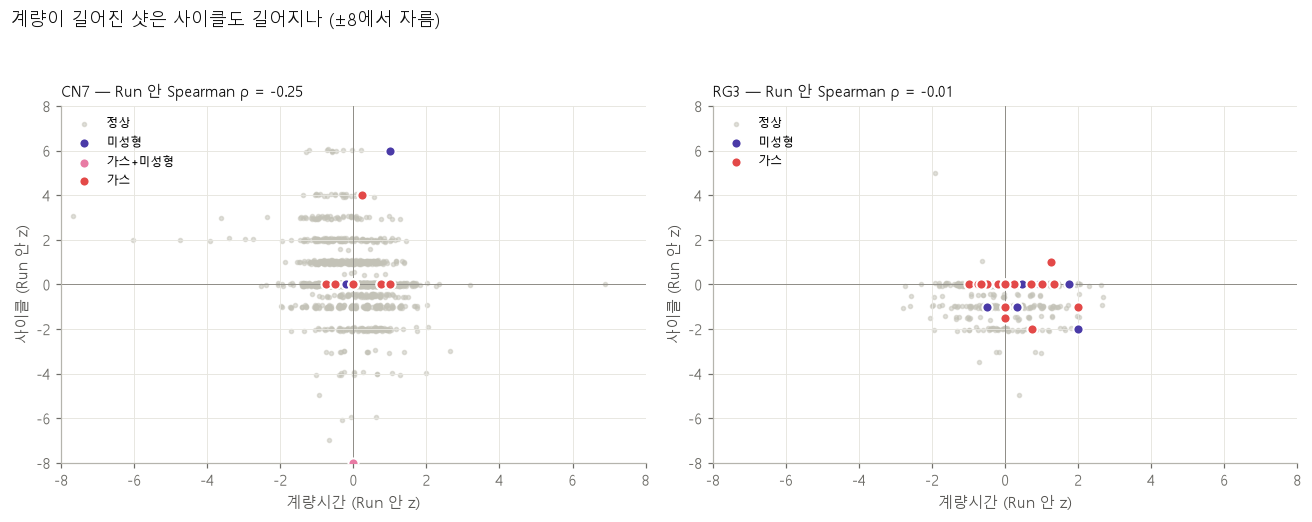

In [2]:
D, V, PR, CP, DL = {}, {}, [], [], []
for p in PRODUCTS:
    D[p], _ = load_product(p)
    pr, cp, dl, V[p] = metering_cycle_link(D[p], p)
    PR.append(pr); CP.append(cp); DL.append(dl)
PR, CP, DL = [pd.concat(x, ignore_index=True) for x in (PR, CP, DL)]
for n, t in [('per_run', PR), ('components', CP), ('delta', DL)]:
    t.to_csv(f'{OUT}/meter_cycle_{n}.csv', index=False, encoding='utf-8-sig')
print('① Run별 계량-사이클 상관'); display(PR.round(3))
print('② 사이클 구성요소 (Run 안 표준화 회귀)'); display(CP.round(3))
print('③ 불량 vs 정상 δ — 사이클에서 계량 영향을 빼도 남나')
display(DL.pivot_table(index=['제품', '불량군', '변수'], columns='비교군', values='δ').round(3))
plot_metering_cycle(D, V, save=f'{OUT}/meter_cycle.png')

**읽는 법**
- ρ > 0이고 '사이클|계량 잔차'의 가스 δ가 0 근처로 줄면 → 사이클↑은 계량 지연의 흔적 (열분해 아님)
- ρ ≈ 0이거나 잔차 δ가 그대로 남으면 → 사이클을 늘린 건 다른 동작(형체·취출 등)

## PART 2. 물리 기반 모델
### 2-0. reference (기간 제한 + 적합도 점검)
08에서 전체 기간 reference는 labeled 양품 백분위 중앙값이 0.5에서 크게 벗어났음 → 기간을 줄인 reference를 만들고 점검

In [3]:
REF_PERIOD = ('2020-09-01', '2020-11-30')        # 점검 결과 보고 조정 (라벨 안 보는 기준: 양품 pct 중앙값 ≈ 0.5)
SCALES = json.load(open('./base/reference_scales.json', encoding='utf-8'))
tag = 'all' if REF_PERIOD is None else f'{REF_PERIOD[0]}_{REF_PERIOD[1]}'
FEAT, REF = {}, {}
for p in PRODUCTS:
    FEAT[p] = add_phys(D[p])
    cache = f'./base/ref_{p}_features_{tag}.csv'
    if os.path.exists(cache):
        REF[p] = pd.read_csv(cache, parse_dates=['TimeStamp'])
    else:
        shots = pd.read_csv(f'./base/{p}_shots.csv', parse_dates=['TimeStamp'])
        rs = build_reference(f'./linked/linked_unlabeled_{p}.csv', shots, p, period=REF_PERIOD)
        REF[p] = reference_features(rs, SCALES[p]['steps'], SCALES[p]['fr_step'])
        REF[p].to_csv(cache, index=False, encoding='utf-8-sig')
    REF[p] = add_phys(REF[p])
    print(p, 'reference', REF[p].shape)

[cn7] reference: unlabeled 28,744샷 → 16,353샷, Run 10개 (2020-09-03 ~ 2020-10-19), 이상기록 제거 1634
cn7 reference (16353, 75)
[rg3] reference: unlabeled 29,633샷 → 4,406샷, Run 7개 (2020-09-14 ~ 2020-10-22), 이상기록 제거 0
rg3 reference (4406, 75)


### 2-1. 모델 실행

In [4]:
ALL, REF_Z, SUP_REF = run_phys_models(FEAT, REF)
ALL = pd.concat([ALL, mask_transient(ALL[ALL['method'].str.startswith('E')])], ignore_index=True)
ALL.to_csv(f'{OUT}/oof.csv', index=False, encoding='utf-8-sig')

# reference 적합도: 양품 pct 중앙값 ≈ 0.5, pct≥0.99 비율 ≈ 1% 이어야 점수·임계값이 의미 있음
chk = ALL[(ALL['y'] == 0) & ALL['method'].str.startswith('U_')]
display(chk.groupby(['product', 'method'])['pct'].agg(중앙값='median', 상위1퍼센트=lambda x: (x >= 0.99).mean()).round(3))

  cn7 U_iforest|free 완료
  cn7 U_maha|free 완료
  cn7 U_knn|free 완료
  cn7 U_iforest|phys 완료
  cn7 U_maha|phys 완료
  cn7 U_knn|phys 완료
  cn7 U_iforest|phys_core 완료
  cn7 U_maha|phys_core 완료
  cn7 U_knn|phys_core 완료
  rg3 U_iforest|free 완료
  rg3 U_maha|free 완료
  rg3 U_knn|free 완료
  rg3 U_iforest|phys 완료
  rg3 U_maha|phys 완료
  rg3 U_knn|phys 완료
  rg3 U_iforest|phys_core 완료
  rg3 U_maha|phys_core 완료
  rg3 U_knn|phys_core 완료
  pooled LORO cn7_R1 완료 (학습 불량 33)
  pooled LORO cn7_R2 완료 (학습 불량 47)
  pooled LORO cn7_R3 완료 (학습 불량 47)
  pooled LORO cn7_R4 완료 (학습 불량 47)
  pooled LORO cn7_R5 완료 (학습 불량 47)
  pooled LORO cn7_R6 완료 (학습 불량 46)
  pooled LORO rg3_R1 완료 (학습 불량 47)
  pooled LORO rg3_R2 완료 (학습 불량 42)
  pooled LORO rg3_R3 완료 (학습 불량 37)
  pooled LORO rg3_R4 완료 (학습 불량 43)
  pooled LORO rg3_R5 완료 (학습 불량 41)
  pooled LORO rg3_R6 완료 (학습 불량 40)


중앙값  상위1퍼센트
product method                            
cn7     U_iforest|free       0.768   0.016
        U_iforest|phys       0.603   0.009
        U_iforest|phys_core  0.626   0.004
        U_knn|free           0.786   0.025
        U_knn|phys           0.729   0.016
        U_knn|phys_core      0.754   0.013
        U_maha|free          0.723   0.011
        U_maha|phys          0.542   0.011
        U_maha|phys_core     0.607   0.023
        U_rule|phys          0.703   0.002
rg3     U_iforest|free       0.553   0.007
        U_iforest|phys       0.640   0.020
        U_iforest|phys_core  0.654   0.013
        U_knn|free           0.588   0.027
        U_knn|phys           0.623   0.007
        U_knn|phys_core      0.674   0.012
        U_maha|free          0.543   0.013
        U_maha|phys          0.638   0.008
        U_maha|phys_core     0.619   0.013
        U_rule|phys          0.625   0.007

### 2-2. 비교 (순위 지표)

In [5]:
SUM = evaluate_v2(ALL)
SUM.to_csv(f'{OUT}/summary.csv', index=False, encoding='utf-8-sig')
KEY = ['E2_free', 'E2_phys', 'U_rule|phys', 'E_phys+rule', 'U_knn|phys_core', 'S_logit|sup_phys', 'S_logit|sup_free',
       'E2_free|과도제외', 'E2_phys|과도제외']
cols = ['product', 'method', 'n_def', 'AP', 'AP_lo', 'AP_hi', 'AP/base', 'hit@5%', 'hit@10%',
        'AP_가스', 'hit10_가스', 'AP_미성형', 'hit10_미성형']
for p in PRODUCTS:
    print(f'===== {p.upper()} =====')
    s = SUM[(SUM['product'] == p) & SUM['method'].isin(KEY)]
    display(s[[c for c in cols if c in s]].round(3))

===== CN7 =====


,product,method,n_def,AP,AP_lo,AP_hi,AP/base,hit@5%,hit@10%,AP_가스,hit10_가스,AP_미성형,hit10_미성형
34,cn7,E2_free|과도제외,15,0.146,0.016,0.397,19.180,3/15,4/15,0.012,1/11,0.480,3/4
36,cn7,E2_phys|과도제외,15,0.137,0.009,0.392,17.996,3/15,3/15,0.006,0/11,0.480,3/4
28,cn7,E2_free,15,0.112,0.015,0.348,14.721,3/15,4/15,0.011,1/11,0.359,3/4
32,cn7,E_phys+rule,15,0.109,0.012,0.344,14.365,3/15,4/15,0.009,1/11,0.359,3/4
8,cn7,U_knn|phys_core,15,0.106,0.011,0.343,13.889,3/15,3/15,0.007,0/11,0.359,3/4
30,cn7,E2_phys,15,0.104,0.009,0.340,13.732,3/15,3/15,0.006,0/11,0.359,3/4
9,cn7,U_rule|phys,15,0.091,0.012,0.311,11.993,4/15,5/15,0.009,2/11,0.288,3/4
20,cn7,S_logit|sup_free,15,0.038,0.015,0.115,5.057,3/15,4/15,0.011,1/11,0.088,3/4
22,cn7,S_logit|sup_phys,15,0.024,0.014,0.090,3.215,3/15,3/15,0.011,0/11,0.042,3/4


===== RG3 =====


,product,method,n_def,AP,AP_lo,AP_hi,AP/base,hit@5%,hit@10%,AP_가스,hit10_가스,AP_미성형,hit10_미성형
33,rg3,E_phys+rule,32,0.102,0.055,0.201,1.996,4/32,5/32,0.103,4/22,0.022,1/10
19,rg3,U_rule|phys,32,0.085,0.057,0.182,1.663,2/32,4/32,0.072,3/22,0.027,1/10
37,rg3,E2_phys|과도제외,32,0.066,0.047,0.126,1.295,3/32,6/32,0.058,4/22,0.017,2/10
31,rg3,E2_phys,32,0.065,0.046,0.123,1.267,3/32,6/32,0.057,4/22,0.017,2/10
35,rg3,E2_free|과도제외,32,0.063,0.049,0.100,1.227,1/32,1/32,0.048,1/22,0.021,0/10
18,rg3,U_knn|phys_core,32,0.062,0.046,0.121,1.218,2/32,2/32,0.055,2/22,0.016,0/10
29,rg3,E2_free,32,0.062,0.051,0.093,1.213,1/32,1/32,0.048,1/22,0.020,0/10
26,rg3,S_logit|sup_phys,32,0.060,0.049,0.092,1.176,3/32,4/32,0.045,3/22,0.021,1/10
24,rg3,S_logit|sup_free,32,0.053,0.044,0.083,1.043,3/32,4/32,0.040,2/22,0.018,2/10


### 2-3. F1 (임계값은 테스트 Run을 보지 않음)

In [6]:
F1, PRED = f1_v2(ALL, methods=['E2_free', 'E2_phys', 'U_rule|phys', 'E_phys+rule', 'E2_phys|과도제외'])
F1.to_csv(f'{OUT}/f1.csv', index=False, encoding='utf-8-sig')
display(F1.round(3))

,product,method,임계값,F1,Precision,Recall,TP,FP,FN,선택 q
0,cn7,U_rule|phys,pct≥0.99,0.000,0.000,0.000,0,3,15,NaN
1,cn7,U_rule|phys,pct≥0.995,0.000,0.000,0.000,0,3,15,NaN
2,cn7,U_rule|phys,pct≥0.999,0.000,0.000,0.000,0,1,15,NaN
3,cn7,U_rule|phys,LORO 선택,0.000,0.000,0.000,0,4,15,"{'cn7_R1': 0.9995, 'cn7_R2': 0.97, 'cn7_R3': 0..."
4,rg3,U_rule|phys,pct≥0.99,0.054,0.200,0.031,1,4,31,NaN
5,rg3,U_rule|phys,pct≥0.995,0.000,0.000,0.000,0,1,32,NaN
6,rg3,U_rule|phys,pct≥0.999,0.000,0.000,0.000,0,0,32,NaN
7,rg3,U_rule|phys,LORO 선택,0.032,0.032,0.031,1,30,31,"{'rg3_R1': 0.95, 'rg3_R2': 0.95, 'rg3_R3': 0.9..."
8,cn7,E2_free,pct≥0.99,0.122,0.088,0.200,3,31,12,NaN
9,cn7,E2_free,pct≥0.995,0.200,0.200,0.200,3,12,12,NaN


## 해석 가이드
- **미성형** AP·hit에서 `E2_phys`나 `U_rule|phys`가 `E2_free`보다 좋으면 → 물리 변수 선택이 효과 있음
- **가스**는 물리 근거가 있는 지표가 없어서 개선 기대 X → 그대로면 정상 (실패 조건 근거)
- `U_rule|phys`(학습 없음)가 학습 모델과 비슷하면 → **설명 가능한 규칙 하나로 충분** (보고서·현장 적용에 유리)
- 차이가 CI 안이면 '동등' → 변수가 적고 설명 쉬운 쪽 선택
- reference 적합도(2-1 표)가 크게 벗어나면 pooled AP·F1은 신뢰 X, Run 안 hit@k만 볼 것